In [1]:
from pathlib import Path
import os
import sys
import json
import csv

ROOT = Path.cwd()
if not (ROOT / "data" / "manifests").exists():
    ROOT = Path(r"D:\\FILE AND TASK\\TA")
assert (ROOT / "data" / "manifests").exists(), ROOT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["MPLBACKEND"] = "Agg"

try:
    from IPython.display import display, Image
except ImportError:
    def display(item): print(item)
    class Image:
        def __init__(self, filename): self.filename = filename

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Project:", ROOT)
print("Kernel:", sys.executable)


def show_json(path):
    print(path)
    print(json.dumps(json.loads(path.read_text(encoding="utf-8")), ensure_ascii=False, indent=2))


def show_csv(path, rows=30):
    frame = pd.read_csv(path, low_memory=False)
    print(path, "|", len(frame), "baris")
    display(frame if len(frame) <= rows else pd.concat([frame.head(rows // 2), frame.tail(rows // 2)]))
    if len(frame) > rows:
        print("Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.")
    return frame


Project: D:\FILE AND TASK\TA
Kernel: c:\Users\Fabio\AppData\Local\Programs\Python\Python314\python.exe


In [2]:
# Kode eksperimen berasal dari scripts/run_e5_diagnostics.py dan ditempatkan langsung di notebook ini.
# Tidak ada pemanggilan subprocess atau eksekusi file runner eksternal.
# Entry point CLI sengaja tidak dipanggil otomatis agar artefak valid tidak tertimpa.
__file__ = str(ROOT / "scripts" / "run_e5_diagnostics.py")

"""Run E5 diagnostic failure taxonomy from validated E2/E3/E4 artifacts."""

import argparse
import json
import os
import sys
from datetime import datetime, timezone
from pathlib import Path

os.environ["MPLBACKEND"] = "Agg"
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))
from src.mix_noise import mix_audio_at_snr
from src.preprocess import preprocess_audio, TARGET_SR

MANIFEST = ROOT / "data/manifests/dataset_split.csv"
REPS = ("R0", "R1", "R2", "R3")


def atomic_json(path: Path, value: object) -> None:
    temp = path.with_name(path.name + ".tmp")
    if path.exists() or temp.exists(): raise FileExistsError(path)
    with temp.open("xb") as f:
        f.write((json.dumps(value, indent=2, allow_nan=False) + "\n").encode()); f.flush(); os.fsync(f.fileno())
    temp.replace(path)


def mode(top1: pd.Series, score: pd.Series, tau: pd.Series) -> pd.Series:
    return np.select(
        [top1.eq(1) & score.ge(tau), top1.eq(1) & score.lt(tau), top1.eq(0) & score.ge(tau)],
        ["Accepted correct", "Open-set false rejection", "Top-1 confusion above threshold"],
        default="Total retrieval collapse",
    )


def acoustics(y: np.ndarray) -> dict[str, float]:
    return {"spectral_centroid_hz": float(np.mean(librosa.feature.spectral_centroid(y=y, sr=TARGET_SR))),
            "spectral_bandwidth_hz": float(np.mean(librosa.feature.spectral_bandwidth(y=y, sr=TARGET_SR))),
            "mean_rms": float(np.mean(librosa.feature.rms(y=y)))}


def e2_features(e2: Path, queries: pd.DataFrame) -> pd.DataFrame:
    """Reconstruct physical E2 mixtures once per query/condition and verify audit identity."""
    reference = pd.read_csv(e2 / "raw" / "R0_Clean.csv", low_memory=False)
    rows = []
    for condition in ["Clean", "SNR_20dB", "SNR_10dB", "SNR_0dB", "SNR_-5dB"]:
        source = reference if condition == "Clean" else pd.read_csv(e2 / "raw" / f"R0_{condition}.csv", low_memory=False)
        for i, (_, item) in enumerate(source.iterrows()):
            if str(item.query_id) != str(queries.iloc[i].recording_id):
                raise ValueError(f"E2 query ordering differs from active manifest at row {i}: {item.query_id}")
            clean = preprocess_audio(str(queries.iloc[i].file_path))
            if condition == "Clean":
                y = clean
            else:
                y, audit = mix_audio_at_snr(clean, float(item.snr_db), seed=int(item.noise_seed), return_audit_info=True)
                if audit["noise_file"] != item.noise_file or not np.isclose(audit["snr_db_achieved"], item.snr_db_achieved, atol=1e-6):
                    raise ValueError(f"E2 mixture audit mismatch: {item.query_id} {condition}")
            row = {"query_id": str(item.query_id), "condition": condition, "acoustic_status": "reconstructed_verified"}
            row.update(acoustics(y)); rows.append(row)
        print(f"E5 acoustic {condition}: {len(source)}/{len(source)}", flush=True)
    return pd.DataFrame(rows)


def main(e2: Path, e3: Path, e4: Path) -> Path:
    e2, e3, e4 = e2.resolve(), e3.resolve(), e4.resolve()
    if json.loads((e2 / "metadata.json").read_text()).get("status") != "complete": raise ValueError("E2 incomplete")
    if json.loads((e3 / "metadata.json").read_text()).get("status") != "complete": raise ValueError("E3 incomplete")
    thresholds = pd.read_csv(e3 / "tables" / "frozen_thresholds.csv")[["representation", "frozen_tau"]]
    queries = pd.read_csv(MANIFEST).query("split_role == 'query_clean'").reset_index(drop=True)
    output = ROOT / "results" / "reproductions" / f"E5_diagnostics_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
    (output / "tables").mkdir(parents=True); (output / "figures").mkdir()

    feature_table = e2_features(e2, queries)
    e2_frames = []
    for rep in REPS:
        for name in ["Clean", "SNR_20dB", "SNR_10dB", "SNR_0dB", "SNR_-5dB"]:
            f = pd.read_csv(e2 / "raw" / f"{rep}_{name}.csv", low_memory=False)
            f["source_experiment"] = "E2"; e2_frames.append(f)
    known_e2 = pd.concat(e2_frames, ignore_index=True).merge(thresholds, on="representation", validate="many_to_one")
    known_e2["failure_mode"] = mode(known_e2.top1_match, known_e2.max_score, known_e2.frozen_tau)
    known_e2 = known_e2.merge(feature_table, on=["query_id", "condition"], validate="many_to_one")
    known_e2["threshold_margin"] = known_e2["max_score"] - known_e2["frozen_tau"]
    known_e2["top1_identity_status"] = "available"

    e4_frames = []
    for rep in REPS:
        f = pd.read_csv(e4 / "raw" / f"E4_{rep}_raw.csv", low_memory=False)
        f["source_experiment"] = "E4"; e4_frames.append(f)
    known_e4 = pd.concat(e4_frames, ignore_index=True).merge(thresholds, on="representation", validate="many_to_one")
    known_e4["failure_mode"] = mode(known_e4.top1_match, known_e4.max_score, known_e4.frozen_tau)
    known_e4["threshold_margin"] = known_e4["max_score"] - known_e4["frozen_tau"]
    for col in ["top1_recording_id", "top1_species_key", "true_class_max_similarity", "best_other_similarity", "true_vs_other_margin", "spectral_centroid_hz", "spectral_bandwidth_hz", "mean_rms"]: known_e4[col] = np.nan
    known_e4["acoustic_status"] = "not_reconstructed_e4_source_lacks_ranking_and_noisy_audio"
    known_e4["top1_identity_status"] = "not_available_in_e4_raw"
    for col in known_e2.columns:
        if col not in known_e4: known_e4[col] = np.nan
    known = pd.concat([known_e2, known_e4[known_e2.columns]], ignore_index=True)
    failures = known[known.failure_mode.ne("Accepted correct")].copy()
    summary = known.groupby(["source_experiment", "representation", "condition", "failure_mode"], dropna=False).size().reset_index(name="n_queries")

    unknown = pd.read_csv(e3 / "raw" / "test_scores.csv")
    unknown = unknown[unknown.target_type.eq("unknown_control")].copy()
    unknown["open_set_outcome"] = np.where(unknown.predicted_accept.eq(1), "False accept", "Correct reject")
    selected = (failures[failures.source_experiment.eq("E2")].groupby(["representation", "condition", "failure_mode"], group_keys=False)
                .apply(lambda g: g.sample(n=min(2, len(g)), random_state=20261012)).reset_index(drop=True))

    known.to_csv(output / "tables" / "all_query_diagnostics.csv", index=False)
    failures.to_csv(output / "tables" / "failure_cases.csv", index=False)
    summary.to_csv(output / "tables" / "failure_mode_summary.csv", index=False)
    selected.to_csv(output / "tables" / "selected_case_manifest.csv", index=False)
    unknown.to_csv(output / "tables" / "unknown_open_set_diagnostics.csv", index=False)
    plt.figure(figsize=(10,5)); pivot=summary.groupby(["representation","failure_mode"]).n_queries.sum().unstack(fill_value=0); pivot.plot(kind="bar", stacked=True, ax=plt.gca()); plt.tight_layout(); plt.savefig(output / "figures" / "failure_modes_by_representation.png", dpi=180); plt.close()
    plt.figure(figsize=(9,5)); known_e2.boxplot(column="threshold_margin", by="failure_mode", rot=25); plt.suptitle(""); plt.title("Score margin above/below frozen threshold"); plt.tight_layout(); plt.savefig(output / "figures" / "margin_distribution_by_failure_type.png", dpi=180); plt.close()
    plt.figure(figsize=(9,5)); known_e2.boxplot(column="spectral_centroid_hz", by="failure_mode", rot=25); plt.tight_layout(); plt.savefig(output / "figures" / "spectral_features_by_failure_type.png", dpi=180); plt.close()
    report={"status":"PASS_WITH_E4_FIELD_LIMITATION","e2_known_rows":int(len(known_e2)),"e4_known_rows":int(len(known_e4)),"unknown_rows":int(len(unknown)),"selected_cases":int(len(selected)),"e4_limitation":"Top-1 identity, class margins, and acoustic features are unavailable in E4 raw and not inferred."}
    atomic_json(output / "validation_report.json", report)
    atomic_json(output / "metadata.json", {"status":"complete","artifact_schema":"e5_diagnostics_v1","created_utc":datetime.now(timezone.utc).isoformat(),"e2":str(e2.relative_to(ROOT)),"e3":str(e3.relative_to(ROOT)),"e4":str(e4.relative_to(ROOT)),"threshold_source":"E3 frozen_thresholds.csv","e4_diagnostic_limitation":report["e4_limitation"]})
    (output / "README.md").write_text("# E5 diagnostic analysis\n\nE2 mixtures are reconstructed and verified before acoustic features are measured. E4 failure modes use verified `top1_match` and `max_score`; missing ranking fields remain unavailable.\n",encoding="utf-8")
    print(output)
    return output

print("Kode run_e5_diagnostics.py telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.")


Kode run_e5_diagnostics.py telah dimuat di notebook. Jalankan fungsi eksperimen hanya jika memang ingin membuat run baru.


D:\FILE AND TASK\TA\results\reproductions\E5_diagnostics_20261012T091512_868500Z\validation_report.json
{
  "status": "PASS_WITH_E4_FIELD_LIMITATION",
  "e2_known_rows": 6220,
  "e4_known_rows": 100764,
  "unknown_rows": 6200,
  "selected_cases": 120,
  "e4_limitation": "Top-1 identity, class margins, and acoustic features are unavailable in E4 raw and not inferred."
}
D:\FILE AND TASK\TA\results\reproductions\E5_diagnostics_20261012T091512_868500Z\metadata.json
{
  "status": "complete",
  "artifact_schema": "e5_diagnostics_v1",
  "created_utc": "2026-10-12T09:18:23.227333+00:00",
  "e2": "results\\reproductions\\E2_controlled_20261012T021600_897497Z",
  "e3": "results\\reproductions\\E3_open_set_20261012T022548_802536Z",
  "e4": "results\\reproductions\\E4_5sites_20261011T213404_350219Z",
  "threshold_source": "E3 frozen_thresholds.csv",
  "e4_diagnostic_limitation": "Top-1 identity, class margins, and acoustic features are unavailable in E4 raw and not inferred."
}
D:\FILE AND TASK\T

,source_experiment,representation,condition,failure_mode,n_queries
0,E2,R0,Clean,Accepted correct,22
1,E2,R0,Clean,Open-set false rejection,35
2,E2,R0,Clean,Top-1 confusion above threshold,36
3,E2,R0,Clean,Total retrieval collapse,218
4,E2,R0,SNR_-5dB,Open-set false rejection,23
...,...,...,...,...,...
154,E4,R3,SNR_10dB,Total retrieval collapse,3740
155,E4,R3,SNR_20dB,Accepted correct,180
156,E4,R3,SNR_20dB,Open-set false rejection,220
157,E4,R3,SNR_20dB,Top-1 confusion above threshold,2080


D:\FILE AND TASK\TA\results\reproductions\E5_diagnostics_20261012T091512_868500Z\tables\selected_case_manifest.csv | 120 baris


,query_id,species_key,author,snr_db,top1_recording_id,top1_species_key,top1_similarity,true_class_max_similarity,best_other_similarity,true_vs_other_margin,...,source_experiment,signal_power,noise_power_before_scaling,frozen_tau,acoustic_status,spectral_centroid_hz,spectral_bandwidth_hz,mean_rms,threshold_margin,top1_identity_status
0,XC105844,lessho1,Colin Trainor,999,XC576635,lessho1,0.988763,0.988763,0.981327,0.007436,...,E2,NaN,NaN,0.995752,reconstructed_verified,2576.480206,1590.896309,0.030332,-0.006989,available
1,XC152203,colkin1,Mike Nelson,999,XC69653,colkin1,0.992526,0.992526,0.989157,0.003369,...,E2,NaN,NaN,0.995752,reconstructed_verified,2416.760559,2260.551798,0.037364,-0.003226,available
2,XC19846,rubcuc1,David Farrow,999,XC737850,subwar1,0.997812,0.997080,0.997812,-0.000732,...,E2,NaN,NaN,0.995752,reconstructed_verified,4257.642613,3198.846385,0.024465,0.002060,available
3,XC214418,comior1,Paulo Alves,999,XC179384,moutai1,0.996310,0.988565,0.996310,-0.007745,...,E2,NaN,NaN,0.995752,reconstructed_verified,3739.159405,3369.744672,0.028862,0.000558,available
4,XC612584,latnig1,Teus Luijendijk,999,XC395510,moutai1,0.990208,0.974308,0.990208,-0.015900,...,E2,NaN,NaN,0.995752,reconstructed_verified,1286.756426,1752.978883,0.048930,-0.005544,available
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,XC215404,suncuc1,Paulo Alves,20,XC68067,suncuc1,0.444102,0.444102,0.443911,0.000191,...,E2,0.0025,0.0025,0.488838,reconstructed_verified,3725.480420,3479.208886,0.049277,-0.044736,available
116,XC151826,gpipig1,Mike Nelson,20,XC746427,olbsun1,0.509357,0.356441,0.509357,-0.152916,...,E2,0.0025,0.0025,0.488838,reconstructed_verified,4078.485295,3215.366604,0.050057,0.020518,available
117,XC90717,horbab1,Fabian Ducry & David Marques,20,XC206063,lessho1,0.544455,0.220871,0.544455,-0.323584,...,E2,0.0025,0.0025,0.488838,reconstructed_verified,6300.482062,3750.036882,0.032849,0.055617,available
118,XC33652,hoopit1,Tjalle Boorsma,20,XC737849,lessho1,0.434684,0.343267,0.434684,-0.091417,...,E2,0.0025,0.0025,0.488838,reconstructed_verified,5992.436037,3868.137657,0.042665,-0.054154,available


D:\FILE AND TASK\TA\results\reproductions\E5_diagnostics_20261012T091512_868500Z\tables\unknown_open_set_diagnostics.csv | 6200 baris


,representation,condition,snr_db,query_id,target_type,ground_truth,similarity_score,frozen_tau,predicted_accept,noise_file,open_set_outcome
0,R0,Clean,999,UNK_TEST_BIRD_001,unknown_control,0,0.990233,0.995752,0,None (Clean),Correct reject
1,R0,Clean,999,UNK_TEST_BIRD_002,unknown_control,0,0.990644,0.995752,0,None (Clean),Correct reject
2,R0,Clean,999,UNK_TEST_BIRD_003,unknown_control,0,0.991860,0.995752,0,None (Clean),Correct reject
3,R0,Clean,999,UNK_TEST_BIRD_004,unknown_control,0,0.995203,0.995752,0,None (Clean),Correct reject
4,R0,Clean,999,UNK_TEST_BIRD_005,unknown_control,0,0.994389,0.995752,0,None (Clean),Correct reject
5,R0,Clean,999,UNK_TEST_BIRD_006,unknown_control,0,0.996560,0.995752,1,None (Clean),False accept
6,R0,Clean,999,UNK_TEST_BIRD_007,unknown_control,0,0.984639,0.995752,0,None (Clean),Correct reject
7,R0,Clean,999,UNK_TEST_BIRD_008,unknown_control,0,0.995055,0.995752,0,None (Clean),Correct reject
8,R0,Clean,999,UNK_TEST_BIRD_009,unknown_control,0,0.994541,0.995752,0,None (Clean),Correct reject
9,R0,Clean,999,UNK_TEST_BIRD_010,unknown_control,0,0.981283,0.995752,0,None (Clean),Correct reject


Tampilan adalah sampel; CSV lengkap tetap berada di path di atas.


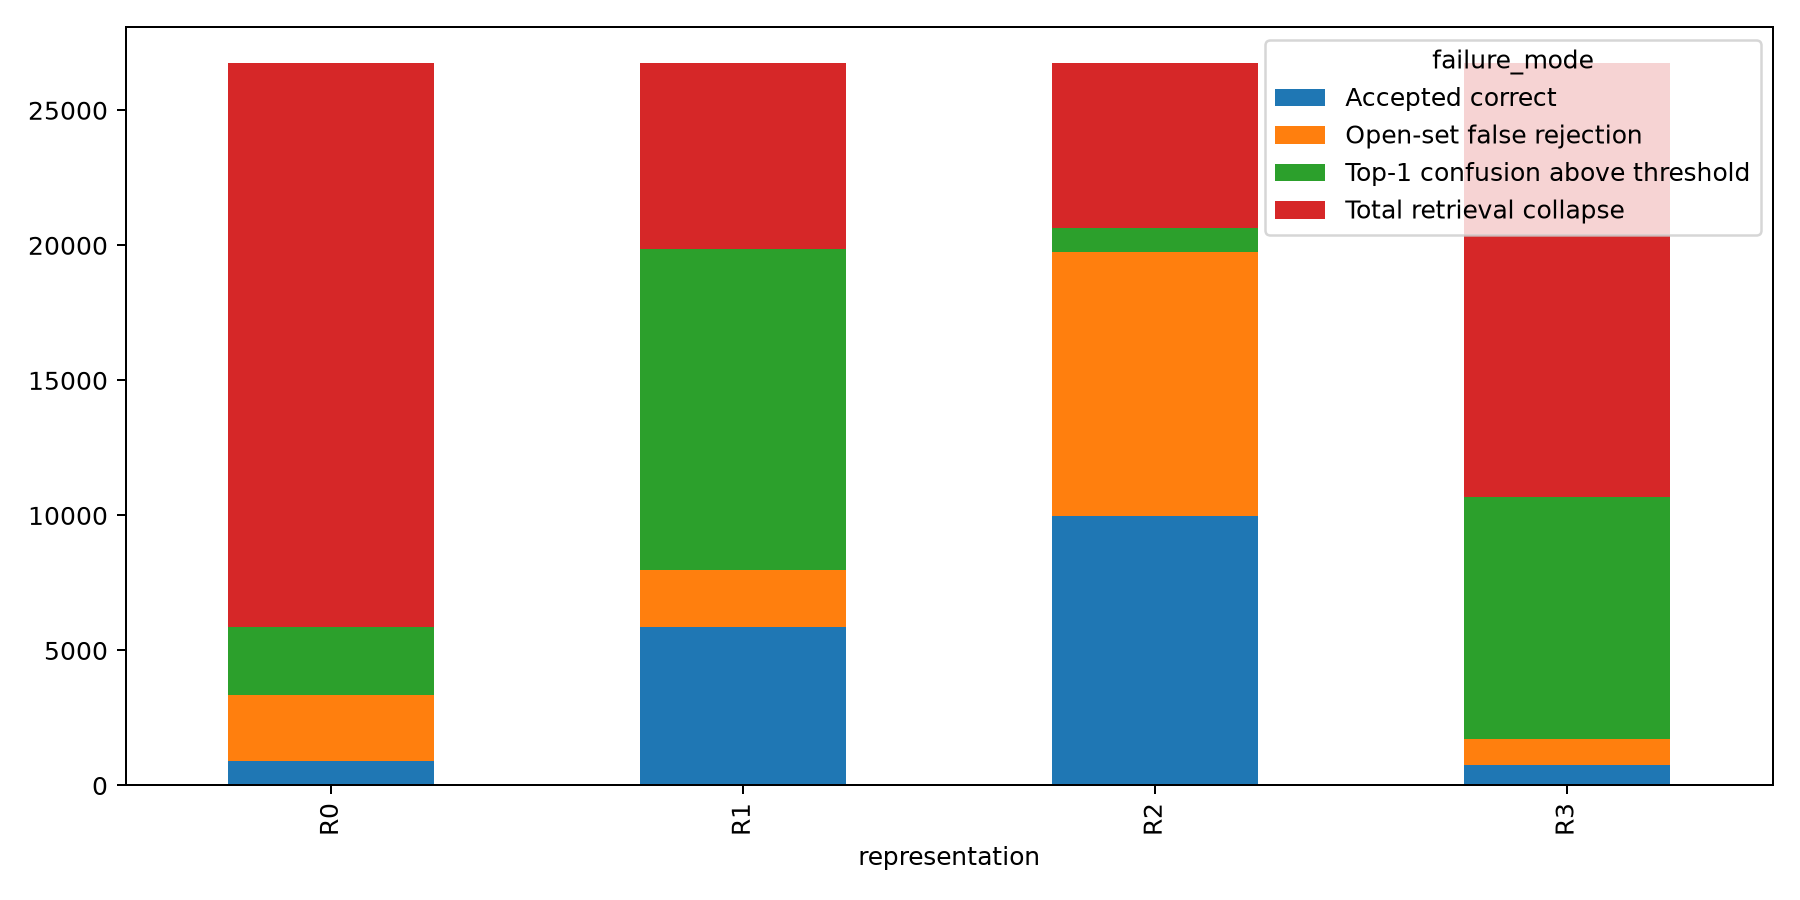

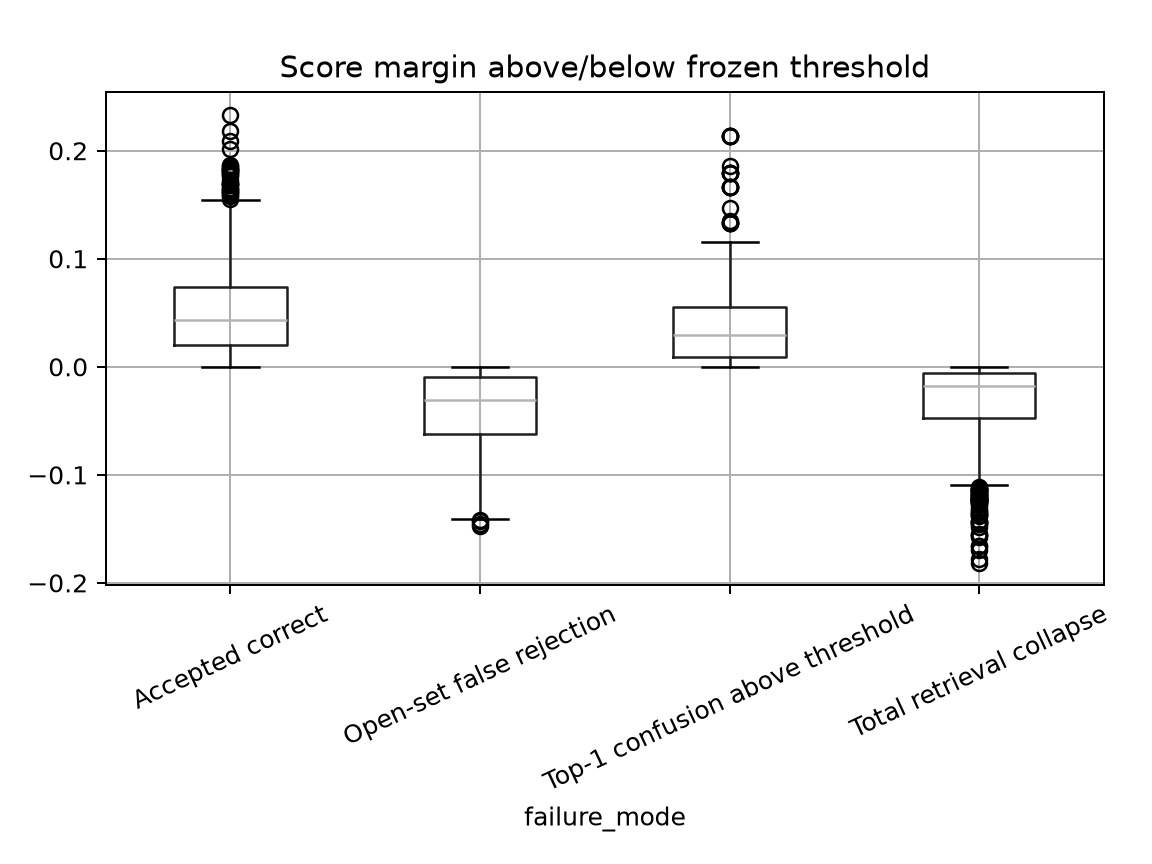

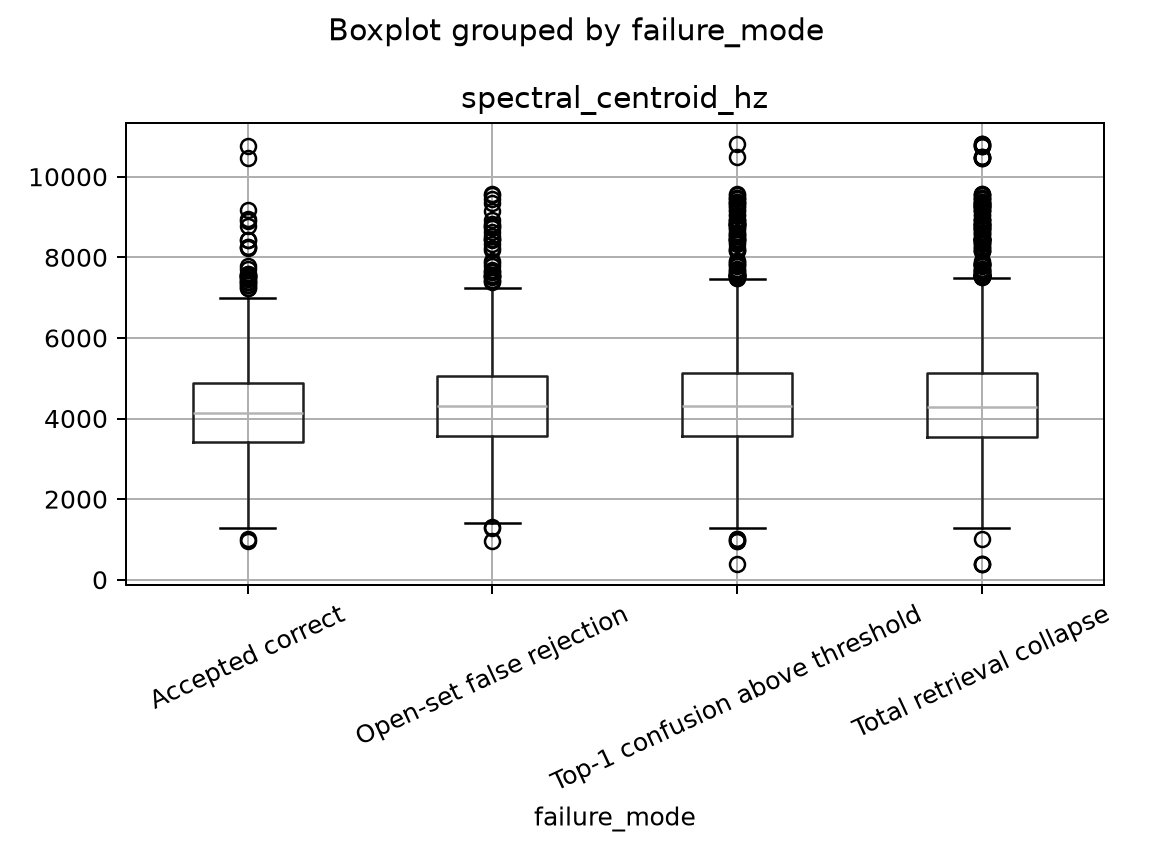

Seluruh diagnostik per-query: D:\FILE AND TASK\TA\results\reproductions\E5_diagnostics_20261012T091512_868500Z\tables\all_query_diagnostics.csv
Seluruh kasus kegagalan: D:\FILE AND TASK\TA\results\reproductions\E5_diagnostics_20261012T091512_868500Z\tables\failure_cases.csv


In [3]:
run = ROOT / "results/reproductions/E5_diagnostics_20261012T091512_868500Z"
show_json(run / "validation_report.json")
show_json(run / "metadata.json")
show_csv(run / "tables/failure_mode_summary.csv", rows=200)
show_csv(run / "tables/selected_case_manifest.csv", rows=120)
show_csv(run / "tables/unknown_open_set_diagnostics.csv", rows=30)
for name in ("failure_modes_by_representation.png", "margin_distribution_by_failure_type.png", "spectral_features_by_failure_type.png"):
    display(Image(filename=str(run / "figures" / name)))
print("Seluruh diagnostik per-query:", run / "tables/all_query_diagnostics.csv")
print("Seluruh kasus kegagalan:", run / "tables/failure_cases.csv")
